# 1. PRESENTACIÓN DEL DATASET

- **¿Qué es?:** Es un dataset de enfermedades cardiovasculares obtenido de Kaggle. Esta formado por 70.000 registros y 13 columnas.
- **¿Qué contiene?:** 

| Columna | Tipo de dato | Explicación |
|---|---|---|
| `id` | Identificador | Número único que identifica a cada paciente |
| `age` | Numérico | Edad del paciente en días (más adelante la pasamos a años) |
| `gender` | Categórico | Sexo del paciente: 1 = mujer, 2 = hombre |
| `height` | Numérico | Altura en centímetros |
| `weight` | Numérico | Peso en kilogramos |
| `ap_hi` | Numérico | Presión arterial sistólica ("alta") en mmHg |
| `ap_lo` | Numérico | Presión arterial diastólica ("baja") en mmHg |
| `cholesterol` | Categórico | Nivel de colesterol: 1 = normal, 2 = alto, 3 = muy alto |
| `gluc` | Categórico | Nivel de glucosa: 1 = normal, 2 = alto, 3 = muy alto |
| `smoke` | Binario | Si el paciente fuma: 0 = no, 1 = sí |
| `alco` | Binario | Si el paciente consume alcohol: 0 = no, 1 = sí |
| `active` | Binario | Si el paciente hace actividad física: 0 = no, 1 = sí |
| `cardio` | Binario | Presencia de enfermedad cardiovascular: 0 = no, 1 = sí |


- **¿Pregunta que nos interesa responder sobre este conjunto de datos?:** ¿qué factores (presión arterial, colesterol, IMC, edad) se asocian más con tener enfermedad cardiovascular?

# 2. LIMPIEZA Y PREPROCESAMIENTO DE LOS DATOS

En primer lugar, importamos las librerías necesarias (`pandas` y `numpy`), definimos las rutas de entrada y salida, y cargamos el dataset original (`cardio_train.csv`) separado por punto y coma (`;`) ademas usamos (`.shape`) para comprobar sus dimensiones iniciales.

In [148]:
import pandas as pd
import numpy as np

#rutas
input="../data/raw/cardio_train.csv"
output="../data/processed/cardio_train_clean.csv"

#lecturas
data=pd.read_csv(input, sep=";")
print(data.shape)

(70000, 13)


## 2.1. Eliminación de duplicados

Comprobamos si existen filas duplicadas en el conjunto de datos y las eliminamos. Esto es importante para evitar que registros repetidos generen errores al realizar los posteriores analisis y graficas.

In [149]:
'''#eliminacion de duplicados
duplicados= data.duplicated().sum()
data.drop_duplicates(inplace=True)
print(f"{duplicados} removed")'''

'#eliminacion de duplicados\nduplicados= data.duplicated().sum()\ndata.drop_duplicates(inplace=True)\nprint(f"{duplicados} removed")'

In [150]:
columnas = data.columns.drop("id")
duplicados = data.duplicated(subset=columnas).sum()
data = data.drop_duplicates(subset=columnas)
print(f"{duplicados} removed")

24 removed


## 2.2. Conversión de la edad a años

En el dataset original la variable `age` viene expresada en días. La dividimos entre `365.25` (teniendo en cuenta los años bisiestos) y la convertimos a número entero para trabajar con la edad en años, que es mucho más interpretable.

In [151]:
#edad a años
data["age"]=(data["age"]/365.25).astype(int)
print(data["age"].iloc[0])

50


## 2.3. Primer filtrado de valores extremos o errores de registro (variables continuas)

Filtramos valores biológicamente improbables o producidos por errores de introducción de datos en variables numéricas:
- **Altura (`height`)**: mayor de 100 cm.
- **Peso (`weight`)**: mayor de 30 kg.
- **Edad (`age`)**: menor de 110 años.
- **Presión arterial sistólica (`ap_hi`)**: entre 50 y 250 mmHg.
- **Presión arterial diastólica (`ap_lo`)**: entre 30 y 150 mmHg.

De esta forma eliminamos *outliers* irreales (como presiones negativas o de miles de mmHg) que distorsionarían las medias y gráficas.

In [152]:
#primer filtrado de posibles errores 
antes=data.shape[0]

data=data[(data["height"]>100) & (data["weight"]>30) & (data["height"]<220) & (data["weight"]<200) & (data["age"]<110) & (data["ap_hi"]>=50) 
          & (data["ap_hi"]<=250) & (data["ap_lo"]>=30) & (data["ap_lo"]<=150)]

elim= antes- data.shape[0]
print(f"{elim} removed")

1280 removed


## 2.4. Limpieza de variables categóricas

Verificamos que todas las variables categóricas y binarias contengan únicamente los códigos válidos definidos en la descripcción del dataset de kaggel:
- `cholesterol` y `gluc`: valores `1` (normal), `2` (alto) o `3` (muy alto).
- `smoke`, `alco`, `active` y `cardio`: valores binarios `0` (no/sano) o `1` (sí/enfermo).

Así garantizamos la integridad de las categorías antes de agrupar o graficar.

In [153]:
#limpieza de datos categoricos
antes2= data.shape[0]

data=data[(data["cholesterol"].isin([1, 2, 3])) & (data["gluc"].isin([1,2,3]))
          & (data["smoke"].isin([0,1])) & (data["alco"].isin([0,1])) & (data["active"].isin([0,1]))
          & (data["cardio"].isin([0,1]))]

elim2= antes2- data.shape[0]
print(f" {elim2} removed")

 0 removed


## 2.5. Coherencia fisiológica en la presión arterial

Eliminamos los registros en los que la presión diastólica (`ap_lo`, baja) sea mayor o igual que la presión sistólica (`ap_hi`, alta), ya que fisiológicamente no es posible y corresponde a un error de medición o transcripción.

In [154]:
#elimiacion diastolica > sistolica (no es posible)
antes3= data.shape[0]
data=data[data["ap_hi"]>data["ap_lo"]]
elim3= antes3-data.shape[0]
print(f"{elim3} removed")

88 removed


## 2.6. Eliminación de valores nulos

Contabilizamos y eliminamos cualquier fila que tenga valores faltantes (`NaN`), asegurando que el dataset final esté completo y no produzca errores en los cálculos posteriores.

In [155]:
#elimiacion de nulos
antes4=data.shape[0]
nulos= data.isnull().sum().sum()
data.dropna(inplace=True)
elim4=antes4- data.shape[0]
print(f"{nulos} nulos eliminados de {elim4} filas")

0 nulos eliminados de 0 filas


## 2.7. Cálculo del Índice de Masa Corporal (IMC / BMI) y exportación

Creamos una nueva variable `bmi` (Índice de Masa Corporal) a partir del peso en kg y la altura en metros ($\text{IMC} = \frac{\text{peso}}{\text{altura}^2}$), redondeada a un decimal. Esta variable sintetiza la relación peso-altura y es un indicador clave de riesgo cardiovascular. Finalmente, guardamos el dataset limpio en `data/processed/cardio_train_clean.csv`.

In [156]:
#imc
data["bmi"]=(data["weight"]/((data["height"]/100)**2)).round(1)

#exportacion
data.to_csv(output, index=False)

# 3. REPRESENTACIÓN Y ANALISIS DE LOS DATOS

In [157]:
import pandas as pd
import matplotlib.pyplot as plt

datos=pd.read_csv("../data/processed/cardio_train_clean.csv", sep=",")


## Gráficos ESTÁTICOS

### Grafico del balance sanos enfermos

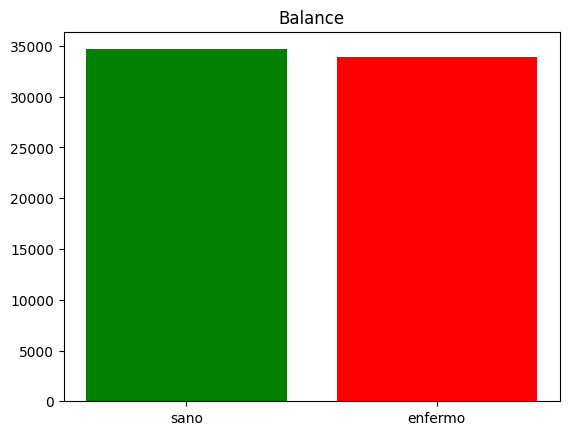

(68608, 14)


In [158]:
conteo= datos["cardio"].value_counts().sort_index()
plt.bar((["sano", "enfermo"]), conteo.values, color=["green", "red"])
plt.title("Balance")
plt.show()

print(datos.shape)

Con este gráfico de barras comprobamos cuántos pacientes del dataset tienen enfermedad cardiovascular y cuántos no. Tras la limpieza nos quedan 68.608 pacientes: 34.661 sanos (50,5 %) y 33.947 enfermos (49,5 %). Las dos barras son casi iguales, así que el conjunto de datos está equilibrado y las comparaciones que hacemos después entre sanos y enfermos no están sesgadas porque haya muchos más pacientes de un grupo que del otro.

### Mapa de corrrelación

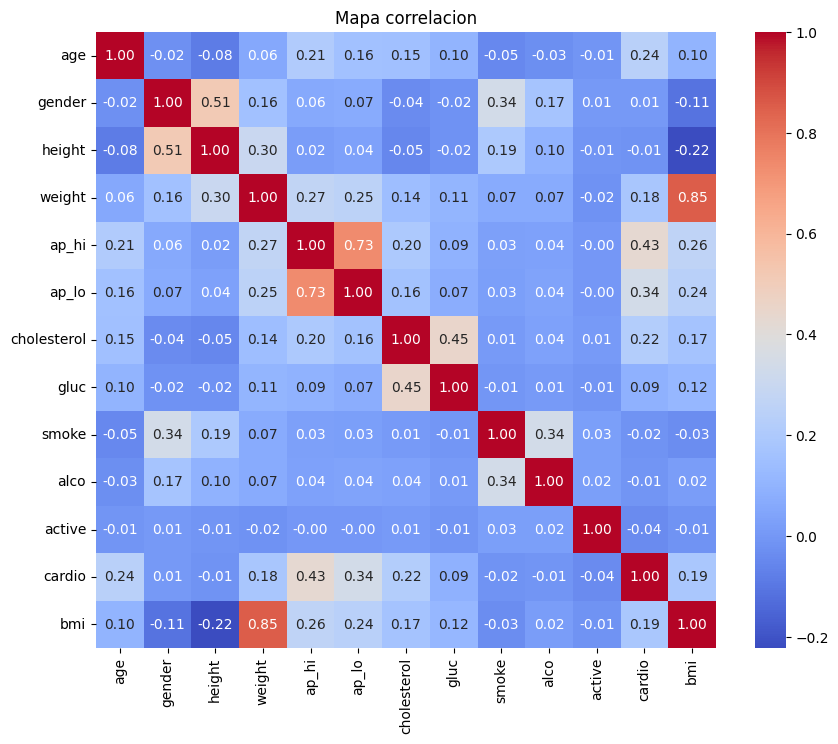

In [159]:
import seaborn as sns

plt.figure(figsize=(10,8))
corr = datos.drop("id", axis=1).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Mapa correlacion")
plt.show()

El mapa de calor muestra la correlación entre todas las variables numéricas. Nos fijamos sobre todo en la fila de `cardio`: las variables más relacionadas con la enfermedad son la presión sistólica (`ap_hi` con 0,43) y la diastólica (`ap_lo` con 0,34), seguidas de la edad (`age` con 0,24), el colesterol (`cholesterol` con 0,22) y el IMC (`bmi` con 0,19). Aun así, ninguna correlación es muy fuerte (no llegan a 0,5), por lo que ninguna variable explica por sí sola la enfermedad. También vemos correlaciones altas entre variables que miden cosas parecidas: `ap_hi` y `ap_lo` (0,73), peso e IMC (0,85, lógico porque el IMC se calcula a partir del peso) y colesterol y glucosa (0,45). Por último, `smoke`, `alco` y `active` tienen una correlación prácticamente nula con `cardio` (entre -0,04 y -0,01) por lo que no tienen apenas relacion con la enfermedad.

### Ranking de correlaciones con cardio

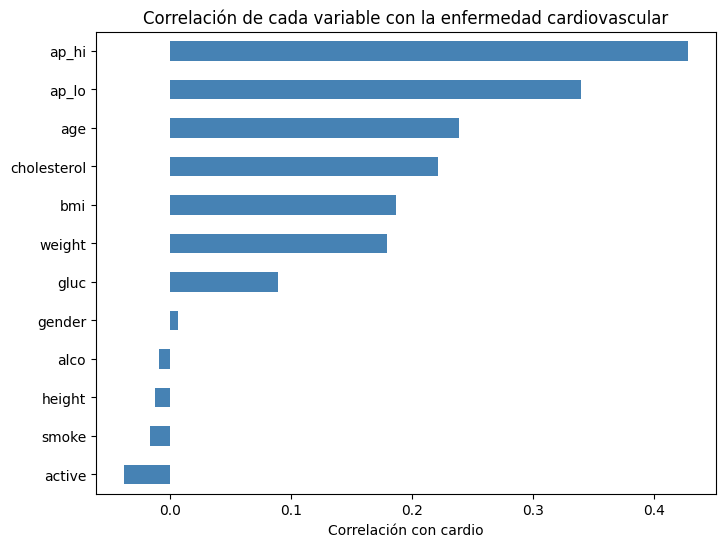

In [160]:
corr_cardio = corr["cardio"].drop("cardio").sort_values()
corr_cardio.plot(kind="barh", figsize=(8,6), color="steelblue")
plt.title("Correlación de cada variable con la enfermedad cardiovascular")
plt.xlabel("Correlación con cardio")
plt.show()

Este gráfico ordena todas las variables según su correlación con `cardio`, así que responde directamente a nuestra pregunta. El orden es: presión sistólica (con más de 0,40), presión diastólica (algo mayor a 0,30), edad (cercano a 0,25), colesterol e IMC (alrededor de 0,20). El peso y la glucosa tienen menos relación, y el sexo, la altura, el alcohol, el tabaco y la actividad física están prácticamente en 0. Hay que tener en cuenta dos cosas: la edad y el colesterol tienen valores muy parecidos, por lo que no podemos afirmar con claridad cuál de los dos pesa más, y la presión sistólica y la diastólica están muy correlacionadas entre sí, así que no son dos factores independientes.

### Grafico de barras por categorias

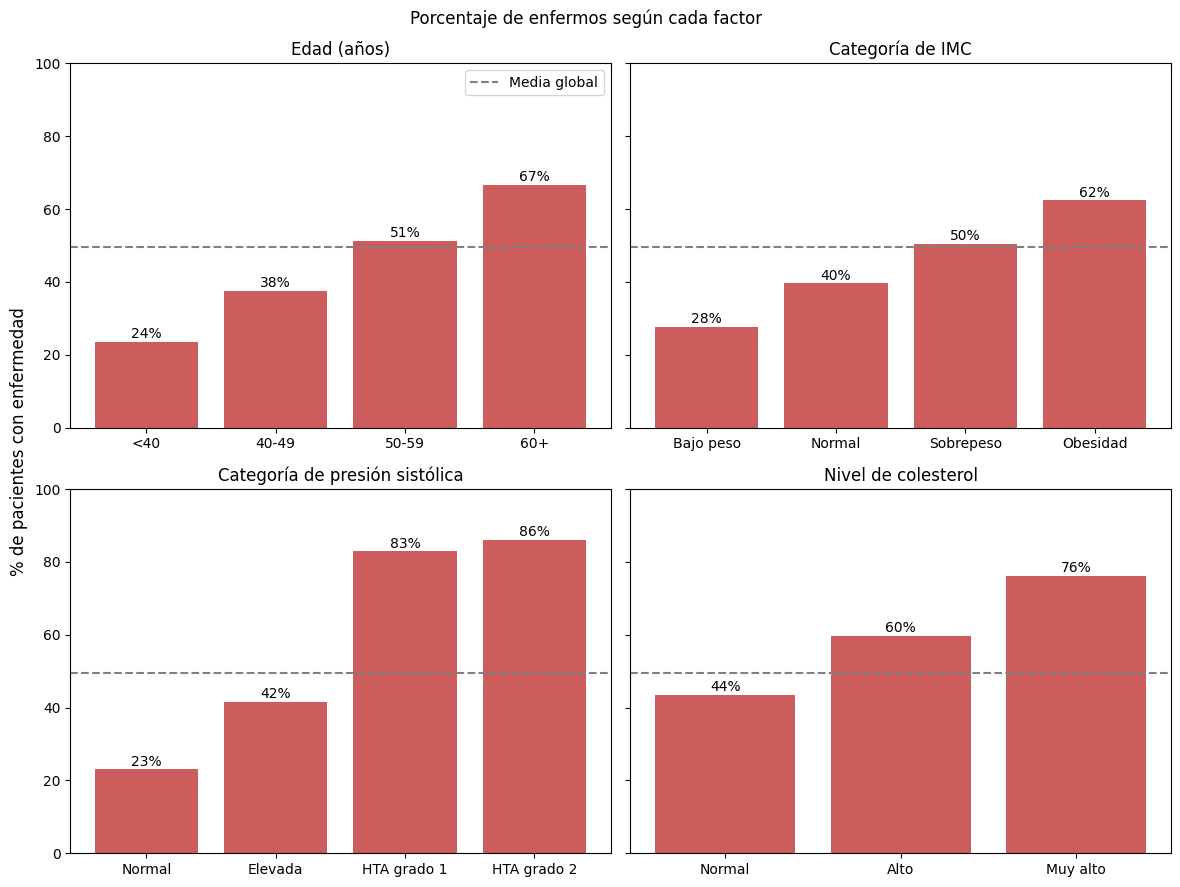

In [161]:
datos["grupo_edad"] = pd.cut(datos["age"], bins=[0, 40, 50, 60, 120],
                             labels=["<40", "40-49", "50-59", "60+"], right=False)
datos["categoria_imc"] = pd.cut(datos["bmi"], bins=[0, 18.5, 25, 30, 100],
                                labels=["Bajo peso", "Normal", "Sobrepeso", "Obesidad"], right=False)
datos["categoria_tension"] = pd.cut(datos["ap_hi"], bins=[0, 120, 140, 160, 300],
                                    labels=["Normal", "Elevada", "HTA grado 1", "HTA grado 2"], right=False)
datos["categoria_colesterol"] = pd.Categorical(
    datos["cholesterol"].map({1: "Normal", 2: "Alto", 3: "Muy alto"}),
    categories=["Normal", "Alto", "Muy alto"], ordered=True)

factores = {
    "grupo_edad": "Edad (años)",
    "categoria_imc": "Categoría de IMC",
    "categoria_tension": "Categoría de presión sistólica",
    "categoria_colesterol": "Nivel de colesterol",
}

media_global = datos["cardio"].mean() * 100

fig, ejes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)

for eje, (columna, titulo) in zip(ejes.flatten(), factores.items()):
    porcentaje = datos.groupby(columna, observed=True)["cardio"].mean() * 100
    eje.bar(porcentaje.index.astype(str), porcentaje.values, color="indianred")
    for i, valor in enumerate(porcentaje.values):
        eje.text(i, valor + 1, f"{valor:.0f}%", ha="center")
    eje.axhline(media_global, color="gray", linestyle="--", label="Media global")
    eje.set_title(titulo)
    eje.set_ylim(0, 100)

ejes[0, 0].legend()
fig.supylabel("% de pacientes con enfermedad")
fig.suptitle("Porcentaje de enfermos según cada factor")
plt.tight_layout()
plt.show()

En estas gráficas vemos el porcentaje de pacientes con enfermedad dentro de cada categoría de los cuatro factores (estos 4 factores son los que se han identificado en el grafico anterior que estan mas relacionados con la enferemedad), de forma que podemos compararlos en la misma escala. Donde la línea gris es la media global, cerca del 50 %.

- **Presión sistólica:** es el factor con mayor diferencia entre categorías. Con tensión normal (<120 mmHg) enferma el 23 % de los pacientes, con tensión elevada (120-139) el 42 % y con HTA grado 1 (140-159) el 83 %, llegando al 86 % en HTA grado 2 (≥160). El mayor salto se produce al pasar de "Elevada" a "HTA grado 1".
- **Edad:** el riesgo aumenta de forma progresiva, del 24 % en menores de 40 años al 67 % a partir de los 60.
- **Colesterol:** pasa del 44 % con nivel normal al 60 % con nivel alto y al 76 % con nivel muy alto.
- **IMC:** también sigue la misma tendencia, aunque más suave: del 40 % con peso normal al 50 % con sobrepeso y al 62 % con obesidad (en bajo peso es el 28 %).

En los cuatro factores, cuanto peor es la categoría, mayor es el porcentaje de enfermos, pero la presión arterial es la que más separa a los pacientes, lo que coincide con el ranking de correlaciones. Hay que tener en cuenta que las categorías las hemos definido nosotros y que para la tensión solo usamos la presión sistólica.

## Grafico INTERACTIVO

In [162]:
import plotly.express as px

datos["enfermedad"] = datos["cardio"].map({0: "Sano", 1: "Enfermo"})

fig = px.histogram(datos, x="ap_hi", color="enfermedad", barmode="overlay",
                   nbins=50, opacity=0.6,
                   labels={"ap_hi": "Presión sistólica (mmHg)", "enfermedad": "Estado"},
                   title="Distribución de la presión sistólica según enfermedad")
fig.show()

Con este histograma interactivo comparamos cómo se distribuye la presión sistólica en sanos y enfermos (al pasar el ratón por las barras se ve el número de pacientes de cada intervalo). La presión media de los sanos es de unos 120 mmHg y la de los enfermos de unos 134. La mayor parte de los sanos tienen exactamente 120 mmHg, mientras que en los enfermos hay muchos más pacientes con valores altos (140 mmHg o más). Los picos que se ven en 120, 130 o 140 se deben a que la presión suele anotarse con valores redondeados. Esto confirma de forma visual lo que veíamos en el ranking: la presión sistólica elevada se asocia con tener enfermedad cardiovascular.

## Gráfico DASHBOARD

In [163]:
'''from dash import Dash, dcc, html, Input, Output
import plotly.express as px

app = Dash(__name__)

app.layout = html.Div([
    html.H1("Dashboard cardiovascular"),
    dcc.Dropdown(
        id="variable",
        options=["categoria_tension", "cholesterol", "categoria_imc", "grupo_edad"],
        value="categoria_tension",
        clearable=False,
    ),
    dcc.Graph(id="grafico_riesgo"),
    dcc.Graph(id="grafico_edad"),
])

@app.callback(
    Output("grafico_riesgo", "figure"),
    Output("grafico_edad", "figure"),
    Input("variable", "value"),
)
def actualizar(variable):
    porcentaje = (datos.groupby(variable)["cardio"].mean() * 100).reset_index()
    fig1 = px.bar(porcentaje, x=variable, y="cardio",
                  labels={"cardio": "% con enfermedad"},
                  title=f"Riesgo según {variable}")
    fig2 = px.histogram(datos, x="age", color=variable, barmode="overlay",
                        title=f"Edad según {variable}")
    return fig1, fig2

app.run(jupyter_mode="inline", debug=True)'''

'from dash import Dash, dcc, html, Input, Output\nimport plotly.express as px\n\napp = Dash(__name__)\n\napp.layout = html.Div([\n    html.H1("Dashboard cardiovascular"),\n    dcc.Dropdown(\n        id="variable",\n        options=["categoria_tension", "cholesterol", "categoria_imc", "grupo_edad"],\n        value="categoria_tension",\n        clearable=False,\n    ),\n    dcc.Graph(id="grafico_riesgo"),\n    dcc.Graph(id="grafico_edad"),\n])\n\n@app.callback(\n    Output("grafico_riesgo", "figure"),\n    Output("grafico_edad", "figure"),\n    Input("variable", "value"),\n)\ndef actualizar(variable):\n    porcentaje = (datos.groupby(variable)["cardio"].mean() * 100).reset_index()\n    fig1 = px.bar(porcentaje, x=variable, y="cardio",\n                  labels={"cardio": "% con enfermedad"},\n                  title=f"Riesgo según {variable}")\n    fig2 = px.histogram(datos, x="age", color=variable, barmode="overlay",\n                        title=f"Edad según {variable}")\n    return f

In [164]:
from dash import Dash, dcc, html, Input, Output
import plotly.express as px

app = Dash(__name__)
opciones = ["categoria_tension", "categoria_colesterol", "categoria_imc", "grupo_edad",
            "gluc", "smoke", "alco", "active"]

app.layout = html.Div([
    html.H1("Dashboard cardiovascular"),
    dcc.Dropdown(id="variable", options=opciones, value="categoria_tension", clearable=False),
    dcc.Graph(id="grafico_riesgo"),
    dcc.Graph(id="grafico_pacientes"),
])

@app.callback(
    Output("grafico_riesgo", "figure"),
    Output("grafico_pacientes", "figure"),
    Input("variable", "value"),
)
def actualizar(variable):
    porcentaje = (datos.groupby(variable, observed=True)["cardio"].mean() * 100).reset_index()
    porcentaje[variable] = porcentaje[variable].astype(str)
    orden = list(porcentaje[variable])

    tabla = datos[[variable, "enfermedad"]].copy()
    tabla[variable] = tabla[variable].astype(str)

    fig1 = px.bar(porcentaje, x=variable, y="cardio", category_orders={variable: orden},
                  labels={"cardio": "% con enfermedad"}, range_y=[0, 100],
                  title=f"% de enfermos según {variable}")
    fig2 = px.histogram(tabla, x=variable, color="enfermedad", barmode="group",
                        category_orders={variable: orden, "enfermedad": ["Sano", "Enfermo"]},
                        title=f"Nº de pacientes según {variable}")
    return fig1, fig2

app.run(jupyter_mode="inline", debug=True)

El dashboard tiene un desplegable para elegir una variable (presión sistólica, colesterol, IMC, edad, glucosa, tabaco, alcohol o actividad física) y con ella se actualizan dos gráficos: arriba, el porcentaje de pacientes con enfermedad en cada categoría y, abajo, el número de pacientes sanos y enfermos en cada una. Con las cuatro primeras variables, que son las de nuestra pregunta, vemos las mismas tendencias que en los gráficos anteriores: el porcentaje de enfermos aumenta con la presión, la edad, el colesterol y el IMC. Con la glucosa, el tabaco, el alcohol y la actividad física, que tienen una correlación baja o casi nula con `cardio`, las diferencias entre categorías son mucho menores. El gráfico de abajo nos sirve además para ver cuántos pacientes hay en cada categoría y no fiarnos de porcentajes calculados con pocos pacientes.

# 4. CONCLUSIONES

Nuestra pregunta era qué factores (presión arterial, colesterol, IMC y edad) se asocian más con tener enfermedad cardiovascular. Con los 68.608 pacientes del dataset limpio hemos visto lo siguiente:

- **La presión arterial es el factor que más se asocia con la enfermedad.** Tiene la correlación más alta (0,43 la sistólica y 0,34 la diastólica) y es el factor que más separa a los pacientes: enferma el 23 % de los que tienen tensión normal frente al 83-86 % de los que tienen HTA. 
- **La edad y el colesterol van después, con un peso parecido** (correlaciones de 0,24 y 0,22). El porcentaje de enfermos pasa del 24 % en menores de 40 años al 67 % a partir de los 60, y del 44 % con colesterol normal al 76 % con colesterol muy alto.
- **El IMC tiene una asociación más moderada** (0,19): enferma el 40 % de los pacientes con peso normal y el 62 % de los que tienen obesidad.
- **Otras variables:** la glucosa se relaciona poco (0,09) y el sexo, la altura, el tabaco, el alcohol y la actividad física casi no se relacionan con la enfermedad en este dataset.
- **Visión global:** ninguna variable explica por sí sola la enfermedad (la correlación más alta es 0,43), pero todos los factores de nuestra pregunta siguen la misma tendencia: cuanto peor es la categoría, mayor es el porcentaje de enfermos.

**Limitaciones:**
- Se trata de asociaciones, no de causas. Los factores están relacionados entre sí (por ejemplo, la edad con la presión, o el colesterol con la glucosa), así que parte del efecto de uno puede deberse a otro.
- Cada paciente tiene una sola medición, y los hábitos (tabaco, alcohol, actividad) probablemente los declara el propio paciente, por lo que pueden ser poco fiables.
- Las categorías las hemos definido nosotros y, como la presión se anota redondeada (muchos pacientes tienen justo 120 o 140), los resultados de la presión dependen un poco de dónde pongamos los cortes.
- La limpieza eliminó algo menos del 2 % de los registros originales.